# Notebook 11 – EDA Visualization

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

df = pd.read_csv("target_variable_analysis.csv")

print("Dataset shape:", df.shape)
display(df.head())
print(df.dtypes)

Dataset shape: (20, 6)


,CustomerID,Age,MonthlyIncome,CustomerType,Purchased,HousePrice_Lakhs
0,1001,25,20000,New,No,20
1,1002,32,35000,Returning,Yes,25
2,1003,45,50000,Returning,Yes,30
3,1004,22,18000,New,No,22
4,1005,38,42000,Returning,Yes,35


CustomerID          int64
Age                 int64
MonthlyIncome       int64
CustomerType          str
Purchased             str
HousePrice_Lakhs    int64
dtype: object


### Histogram 

Why selected?

A histogram shows how frequently numerical values occur within intervals. Use it to study a feature's shape, center, spread, and possible skewness.

Why: To understand the age distribution of customers

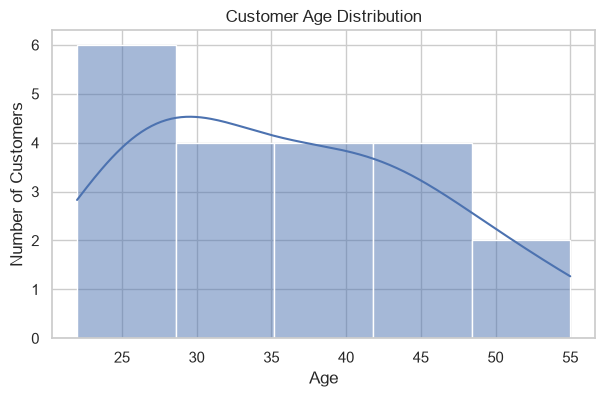

In [6]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Age", bins=5, kde=True)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.show()

Interpretation: Ages range from 22 to 45. With only five customers, the histogram provides a preliminary view rather than a reliable estimate of the overall customer population's distribution.

Insight: Age varies across the observed customers. More records are needed to establish a representative age profile

### Box plot

Why selected?

A box plot summarizes the median, quartiles, variability, and potential outliers

Why: To inspect income variability and potential outliers

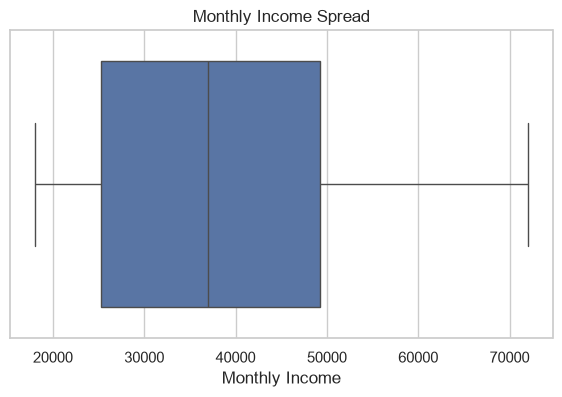

In [7]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="MonthlyIncome")

plt.title("Monthly Income Spread")
plt.xlabel("Monthly Income")
plt.show()

Interpretation: Monthly income ranges from ₹18,000 to ₹50,000. The highest income is not automatically an outlier; it needs to be assessed in context

Insight: The income range may be useful when investigating differences between purchasing and non-purchasing customers

### Bar chart

Why selected?

A bar chart compares a summary statistic across categories

Why: To compare average house prices associated with each customer type

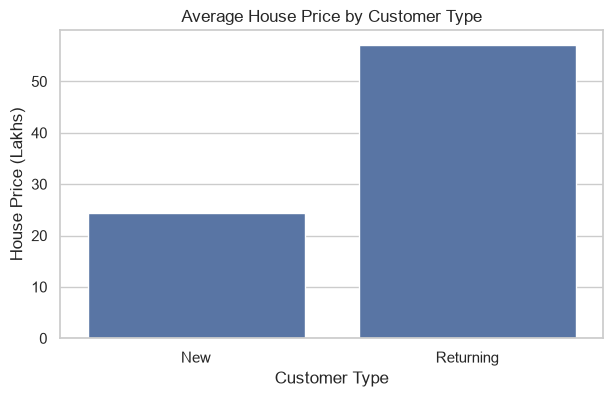

In [8]:
plt.figure(figsize=(7, 4))

sns.barplot(
    data=df,
    x="CustomerType",
    y="HousePrice_Lakhs",
    errorbar=None
)

plt.title("Average House Price by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("House Price (Lakhs)")
plt.show()

Interpretation: In this sample, New customers have an average house price of ₹21 lakhs, while Returning customers have an average of ₹30 lakhs

Insight: Returning customers are associated with higher average house prices in this sample. This does not establish that customer type causes higher house prices

### Count plot 

Why selected?

A count plot shows how many observations belong to each category

Why: To inspect the balance between customers who purchased and those who did not


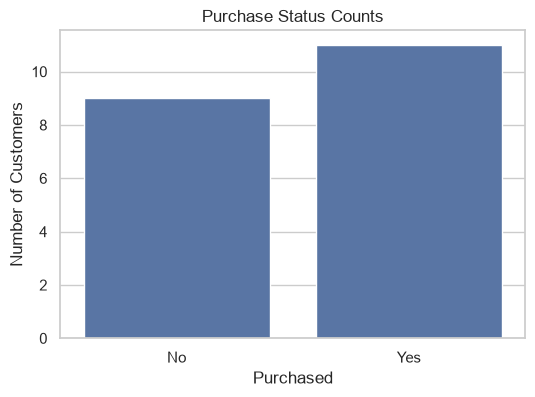

In [9]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="Purchased",
    order=["No", "Yes"]
)

plt.title("Purchase Status Counts")
plt.xlabel("Purchased")
plt.ylabel("Number of Customers")
plt.show()

Interpretation: Three customers purchased and two did not

Insight: The sample contains 60% purchasers and 40% non-purchasers. This is a small sample, so it cannot establish the true purchase rate of the customer population

### Scatter plot

Why selected?

A scatter plot reveals the direction, strength, and shape of a relationship between two numerical variables

Why: To investigate whether higher-income customers are associated with higher house prices.

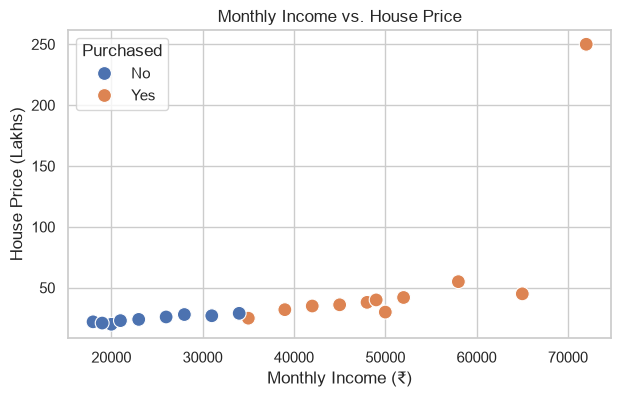

In [10]:
plt.figure(figsize=(7, 4))

sns.scatterplot(
    data=df,
    x="MonthlyIncome",
    y="HousePrice_Lakhs",
    hue="Purchased",
    s=100
)

plt.title("Monthly Income vs. House Price")
plt.xlabel("Monthly Income (₹)")
plt.ylabel("House Price (Lakhs)")
plt.show()

Interpretation: The five observations show a generally positive pattern: higher incomes tend to coincide with higher house prices

Insight: Monthly income may be a useful feature for further analysis of house prices, but five observations are insufficient to establish a reliable relationship

### Line plot

Why selected?

A line plot displays changes in a numerical measure over an ordered time axis

Why: To display house prices in age order. This is useful as an ordered comparison, but age is not a time variable

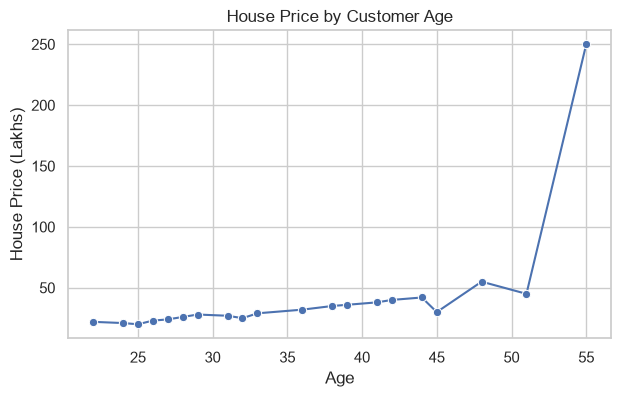

In [11]:
age_order = df.sort_values("Age")

plt.figure(figsize=(7, 4))

sns.lineplot(
    data=age_order,
    x="Age",
    y="HousePrice_Lakhs",
    marker="o"
)

plt.title("House Price by Customer Age")
plt.xlabel("Age")
plt.ylabel("House Price (Lakhs)")
plt.show()

Interpretation: House prices do not increase consistently with age across the five observations

Insight: The relationship between age and house price may be weaker or less consistent than the income relationship. A scatter plot would also be appropriate for this comparison

### Violin plot

Why selected?

A violin plot combines distribution density with a view of how numerical values differ across categories

Why: To compare income distributions between purchasers and non-purchasers.

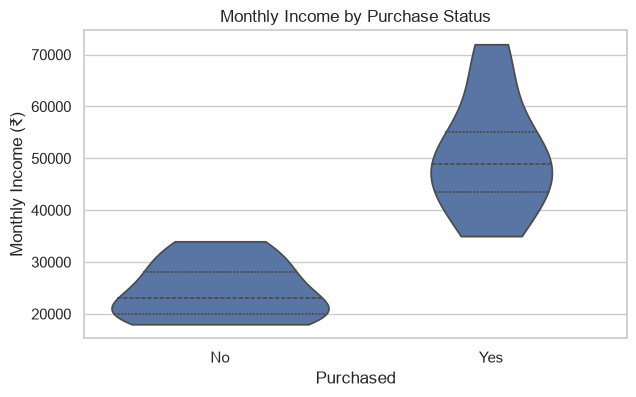

In [12]:
plt.figure(figsize=(7, 4))

sns.violinplot(
    data=df,
    x="Purchased",
    y="MonthlyIncome",
    inner="quartile",
    cut=0
)

plt.title("Monthly Income by Purchase Status")
plt.xlabel("Purchased")
plt.ylabel("Monthly Income (₹)")
plt.show()

Interpretation: The purchasers in this sample have incomes of ₹35,000, ₹42,000, and ₹50,000; non-purchasers have incomes of ₹18,000 and ₹20,000

Insight: Higher income coincides with purchasing in these observations. However, a violin plot based on just two or three values per group is not a reliable representation of the underlying distributions. A strip plot or the raw observations would be more informative here

### Pair plot 

Why selected?

A pair plot provides a matrix of pairwise relationships, with distributions on the diagonal

Why: To explore relationships among age, income, and house price together.

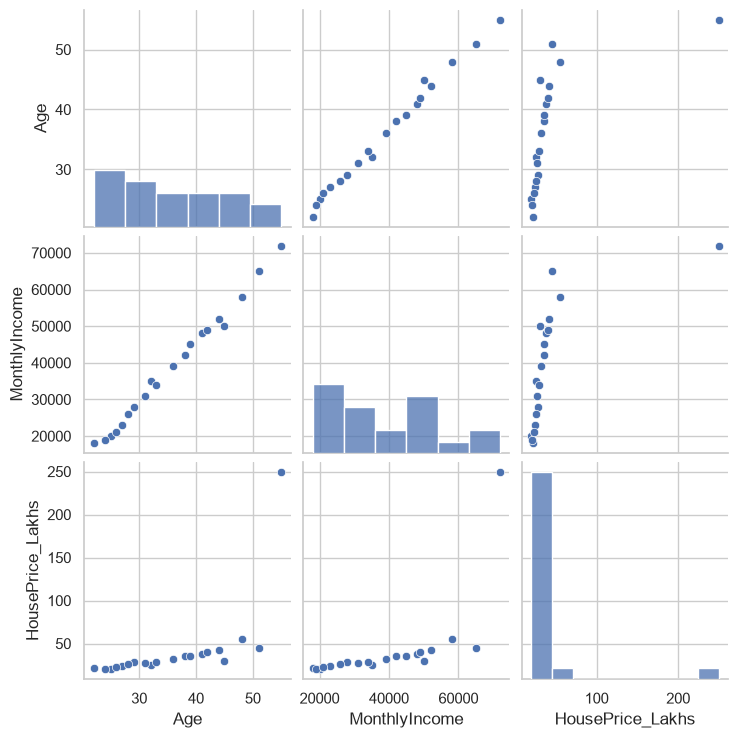

In [13]:
sns.pairplot(
    df[["Age", "MonthlyIncome", "HousePrice_Lakhs"]],
    diag_kind="hist"
)

plt.show()

Interpretation: The scatter panels allow you to compare each pair of numerical features, while the diagonal panels show individual distributions

Insight: This helps identify relationships worth investigating, although the small dataset makes any apparent pattern uncertain

### Heatmap 

Why selected?

A correlation heatmap summarizes pairwise linear correlations among numerical features

Why: To summarize linear relationships among numerical features.

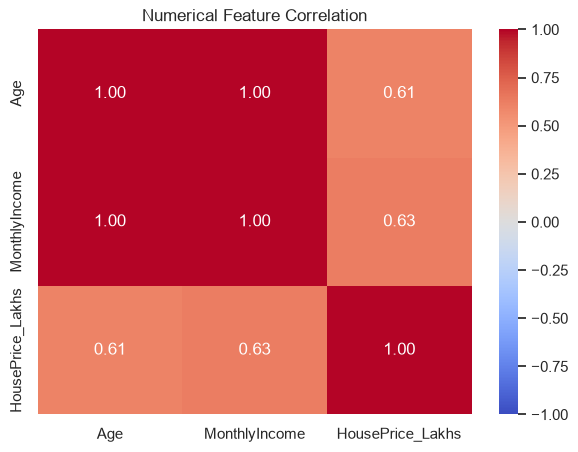

In [14]:
corr = df[
    ["Age", "MonthlyIncome", "HousePrice_Lakhs"]
].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Numerical Feature Correlation")
plt.show()

Interpretation: The heatmap displays Pearson correlation coefficients between −1 and +1

Insight: Use the coefficients to identify potential relationships between age, income, and house price. Treat them as exploratory because the sample has only five records

### Distribution plot

Why selected?

A histogram shows observed frequencies, while a kernel density estimate (KDE) provides a smoothed view of the distribution's shape.

Why: To view the income histogram alongside a smoothed density estimate

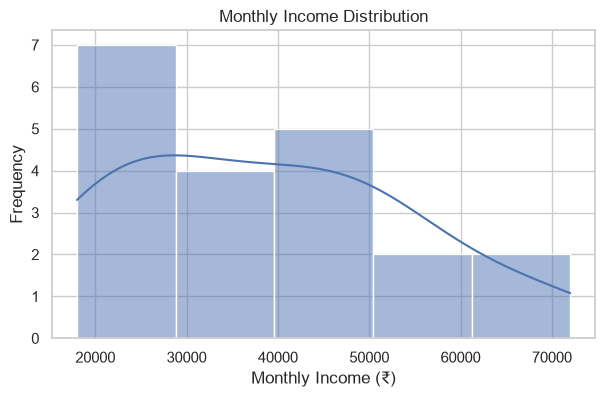

In [15]:
plt.figure(figsize=(7, 4))

sns.histplot(
    data=df,
    x="MonthlyIncome",
    bins=5,
    kde=True
)

plt.title("Monthly Income Distribution")
plt.xlabel("Monthly Income (₹)")
plt.ylabel("Frequency")
plt.show()

Interpretation: The histogram shows the observed income frequencies; the KDE estimates the distribution's shape

Insight: The observed incomes cover a fairly wide range, but five observations are insufficient to infer the true population distribution or its skewness reliably